# Tea Fertilizer Dosage Model - Random Forest Regression

**What this notebook does, in plain words:** the chatbot needs to tell a
farmer how many kilograms of fertilizer to apply, given four things about
their land - how big it is (acres), how many tea plants are on it, how
steep the slope is (0-10), and how many days since it was last fertilized.
We train a model that learns the relationship between those four numbers
and a dosage in kg, then save it in exactly the format
`Chat_Bot/agent/agents/fertilize/tools/dosage_calculator.py` already
expects, so nothing else in the app needs to change.

**Important caveat, read this first:** unlike the disease classifier
notebook (real photos, real labels), there is no historical dataset of
"this land got this much fertilizer and here's how it turned out" sitting
anywhere in this repo. `dataset/generate_dataset.py` (already run - see
section 2) makes one up from a formula, loosely based on how fertilizer
dosing logic usually works (more land and more plants need more product;
longer gaps since the last application need more product; steeper slopes
lose more nutrients to runoff, so a bit extra is applied). **This is a
placeholder, not agronomic truth.** The point of this notebook is the
*pipeline* - train, track, version, swap in a real dataset later - not the
specific numbers it currently produces.

Laid out the same way as the disease classifier project (`dataset/` +
`model/` folders, same MLflow setup) and runs top to bottom the same way.


## 1. Setup

Same idea as the disease notebook: import what we need, fix a random seed
so re-running gives the same synthetic dataset and the same split every
time.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)


## 2. Where the data lives, and the settings we'll use

**What we're doing here:** pointing the notebook at the dataset file
(already generated by `dataset/generate_dataset.py`) and the folder
trained models get saved into - the same two-folder layout
(`dataset/` + `model/`) as the disease classifier project.

**Still true:** that CSV is synthetic, not real agronomic history - see
`dataset/generate_dataset.py`'s docstring for exactly how it was made up,
and the caveat at the top of this notebook.


In [2]:
DATA_PATH = Path("dataset/data/tea_fertilizer_dosage.csv")
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

assert DATA_PATH.exists(), f"Dataset not found at {DATA_PATH}. Run dataset/generate_dataset.py first."

df = pd.read_csv(DATA_PATH)
DATASET_SIZE = len(df)
df.head()


,landSize,plantAmount,degree,days_since_last_fert,dosage_kg
0,4.70,55974,10,339,544.82
1,2.77,23678,10,186,119.50
2,5.19,68053,8,382,591.75
3,4.26,45796,1,265,258.66
4,0.79,5547,3,59,6.66


## 3. A quick look at the generated data

**What we're doing here:** the same sanity check we'd run on a real
dataset - distributions, and how each feature relates to the target - just
to confirm the formula above produced something sane (no negative dosages,
no wild outliers) before training on it.


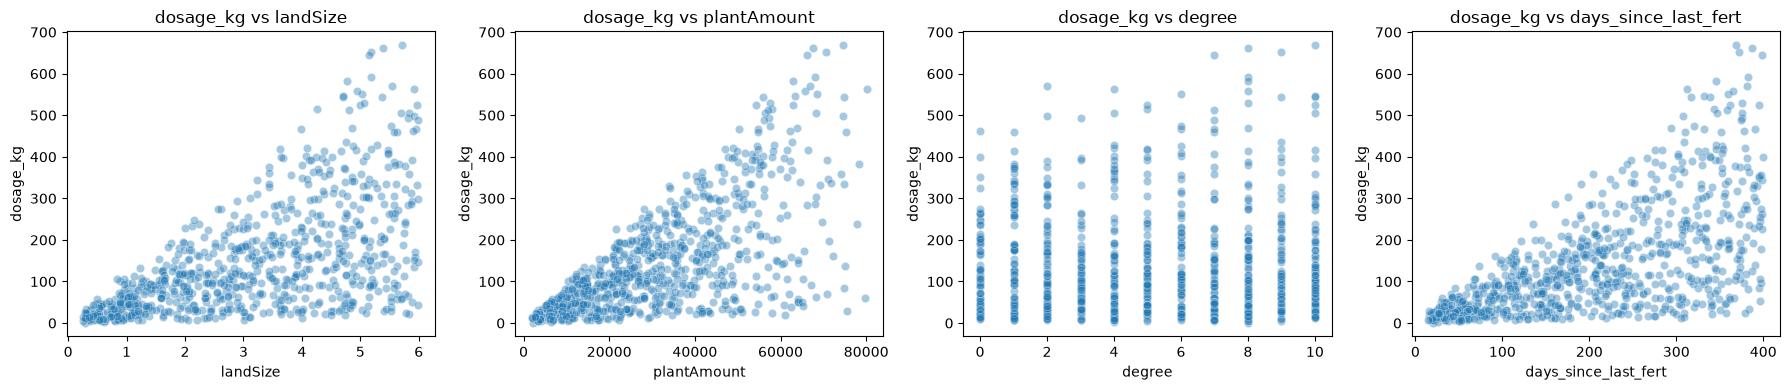

,landSize,plantAmount,degree,days_since_last_fert,dosage_kg
count,800.000000,800.000000,800.000000,800.000000,800.000000
mean,3.092775,31134.952500,5.023750,206.577500,144.757463
std,1.670376,18704.326574,3.185651,111.373703,130.593979
min,0.260000,1905.000000,0.000000,15.000000,1.050000
25%,1.617500,15074.250000,2.000000,112.000000,43.475000
50%,3.085000,28965.000000,5.000000,207.000000,104.110000
75%,4.595000,44793.250000,8.000000,305.000000,200.127500
max,5.990000,80081.000000,10.000000,400.000000,668.520000


In [3]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["landSize", "plantAmount", "degree", "days_since_last_fert"]):
    sns.scatterplot(data=df, x=col, y="dosage_kg", alpha=0.4, ax=ax)
    ax.set_title(f"dosage_kg vs {col}")
plt.tight_layout()
plt.show()

df.describe()


## 4. Train / test split

Same reasoning as the disease notebook: hold back 20% of the data, never
touched during training, as an honest check at the end.


In [4]:
FEATURES = ["landSize", "plantAmount", "degree", "days_since_last_fert"]
TARGET = "dosage_kg"

X_train, X_test, y_train, y_test = train_test_split(
    df[FEATURES], df[TARGET], test_size=0.2, random_state=SEED,
)
print(f"Train: {len(X_train)}  Test: {len(X_test)}")


Train: 640  Test: 160


## 5. Track this run with MLflow

Same setup as the disease classifier notebook: a local SQLite-backed
tracking store, one run per training attempt, params logged up front.

**Why `StandardScaler` and `PolynomialFeatures` in front of a Random
Forest?** Tree-based models don't actually need scaled or polynomial
inputs - they split on raw thresholds either way. This pipeline keeps them
anyway, because that's the exact shape `dosage_calculator.py` expects to
call (`scaler.transform` -> `poly.transform` -> `model.predict`, three
separate steps, not a single `Pipeline` object) - changing that would mean
touching the chatbot's inference code too, which is a separate decision
from "retrain this model." We keep the three-step shape so this is a
drop-in replacement.


In [5]:
import mlflow
import mlflow.sklearn
from pathlib import Path as _Path

# Shared tracking store for ALL ML Models/ sub-projects (the disease
# classifier notebook points here too), so there's one MLflow UI for the
# whole repo instead of a separate server per model. Each project still
# gets its own *experiment* inside that one store (set below).
_SHARED_MLFLOW_DB = (_Path("..") / "mlflow" / "mlflow.db").resolve()
mlflow.set_tracking_uri(f"sqlite:///{_SHARED_MLFLOW_DB}")
mlflow.set_experiment("tea-fertilizer-dosage")

N_ESTIMATORS = 100
MAX_DEPTH = 5
MIN_SAMPLES_SPLIT = 5
POLY_DEGREE = 4

run = mlflow.start_run(run_name="random-forest-poly2-standardscaled")
mlflow.log_params({
    "dataset": "synthetic-formula-v1",
    "dataset_size": DATASET_SIZE,
    "seed": SEED,
    "features": ", ".join(FEATURES),
    "poly_degree": POLY_DEGREE,
    "n_estimators": N_ESTIMATORS,
    "max_depth": MAX_DEPTH,
    "min_samples_split": MIN_SAMPLES_SPLIT,
})
print(f"MLflow run started: {run.info.run_id}")


2026/10/14 19:57:54 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\panka\OneDrive\Desktop\Nimeth\Test\Tea-support-assistant\ML Models\Tea Fertilizer Dosage\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


MLflow run started: 1b942308d60b495da1403300dbdcf29d


## 6. Fit the scaler, polynomial features, and the model

**What we're doing here:** fit each of the three pieces on the training
data only (never on the test data - that would leak information about
data the model is supposed to have never seen), in the same order
`dosage_calculator.py` applies them at prediction time.


In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

poly = PolynomialFeatures(degree=POLY_DEGREE, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)

model = RandomForestRegressor(
    n_estimators=N_ESTIMATORS,
    max_depth=MAX_DEPTH,
    min_samples_split=MIN_SAMPLES_SPLIT,
    random_state=SEED,
)
model.fit(X_train_poly, y_train)

print(f"Trained on {X_train_poly.shape[0]} samples, {X_train_poly.shape[1]} features "
      f"(after degree-{POLY_DEGREE} polynomial expansion of {len(FEATURES)} raw features)")


Trained on 640 samples, 69 features (after degree-4 polynomial expansion of 4 raw features)


## 7. Evaluate on the test set

Same three numbers you'd check for any regression model:
- **MAE** (mean absolute error) - on average, how many kg off is a
  prediction, in the same units as the target, easy to explain to a
  non-technical reader ("off by about X kg on average")
- **RMSE** (root mean squared error) - like MAE but penalises big misses
  more heavily
- **R2** - what fraction of the variation in dosage the model explains
  (1.0 = perfect, 0.0 = no better than always guessing the average)


In [7]:
X_test_scaled = scaler.transform(X_test)
X_test_poly = poly.transform(X_test_scaled)
y_pred = model.predict(X_test_poly)

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.3f} kg")
print(f"RMSE: {rmse:.3f} kg")
print(f"R2:   {r2:.3f}")

mlflow.log_metrics({"mae": mae, "rmse": rmse, "r2": r2})


MAE:  12.428 kg
RMSE: 16.990 kg
R2:   0.981


## 8. Look at where the model is wrong, and what it's using

**What we're doing here:**
- **Predicted vs actual**: points on the diagonal line are exact
  predictions; scatter around it shows typical error size.
- **Feature importances**: which of the 14 polynomial features (4 raw +
  their squares and pairwise products) the forest actually leans on. If
  one dominates, that's worth knowing before trusting the model blindly.


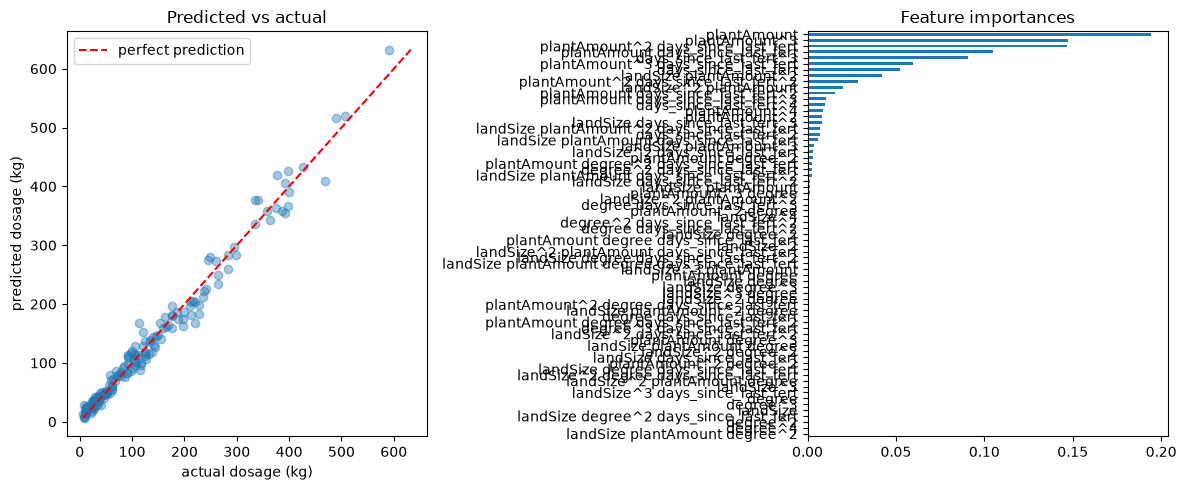

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, y_pred, alpha=0.4)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, "r--", label="perfect prediction")
axes[0].set_xlabel("actual dosage (kg)")
axes[0].set_ylabel("predicted dosage (kg)")
axes[0].set_title("Predicted vs actual")
axes[0].legend()

poly_feature_names = poly.get_feature_names_out(FEATURES)
importances = pd.Series(model.feature_importances_, index=poly_feature_names).sort_values()
importances.plot(kind="barh", ax=axes[1])
axes[1].set_title("Feature importances")

plt.tight_layout()
mlflow.log_figure(fig, "evaluation.png")
plt.show()


## 9. Save the model bundle - same format the chatbot already reads

**What we're doing here:** saving `model`, `scaler`, `poly`, and the
`features` list into one `.pkl` file with `joblib`, at
`model/tea_fertilizer_model.pkl` - the same `model/` folder layout the
disease classifier project uses, and the exact path
`dosage_calculator.py` loads from. This overwrites whatever model was
there before. We also attach a copy of that file to this MLflow run, and
register the Random Forest model itself in the Model Registry so it gets
a version number instead of silently replacing a file with no history.


In [9]:
import joblib

bundle = {
    "model": model,
    "scaler": scaler,
    "poly": poly,
    "features": FEATURES,
}

OUTPUT_PATH = MODEL_DIR / "tea_fertilizer_model.pkl"
joblib.dump(bundle, OUTPUT_PATH)
print(f"Saved trained model to: {OUTPUT_PATH.resolve()}")

mlflow.log_artifact(str(OUTPUT_PATH), artifact_path="bundle")
# serialization_format="pickle": MLflow's newer default ("skops") refuses to
# serialize a RandomForest's internal tree nodes without explicit trust - we
# trust our own just-trained model, and plain pickle matches the rest of this
# pipeline (joblib bundle) anyway.
mlflow.sklearn.log_model(
    model,
    artifact_path="model",
    registered_model_name="tea-fertilizer-dosage-rf",
    serialization_format="pickle",
)

run_id = run.info.run_id
mlflow.end_run()
print(f"\nMLflow run finished: {run_id}")
print('From "ML Models/mlflow", run `mlflow ui --backend-store-uri sqlite:///mlflow.db` to '
      "compare runs across both this project and the disease classifier one, and see "
      "registered model versions.")


2026/10/14 19:57:58 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/10/14 19:57:58 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Saved trained model to: C:\Users\panka\OneDrive\Desktop\Nimeth\Test\Tea-support-assistant\ML Models\Tea Fertilizer Dosage\model\tea_fertilizer_model.pkl



MLflow run finished: 1b942308d60b495da1403300dbdcf29d
From "ML Models/mlflow", run `mlflow ui --backend-store-uri sqlite:///mlflow.db` to compare runs across both this project and the disease classifier one, and see registered model versions.


Registered model 'tea-fertilizer-dosage-rf' already exists. Creating a new version of this model...
Created version '6' of model 'tea-fertilizer-dosage-rf'.


## 10. Sanity check: reload the bundle and predict exactly like the chatbot does

**What we're doing here:** proving the saved file works standalone, by
running the *exact* three-step sequence `dosage_calculator_by_user` uses -
`scaler.transform` -> `poly.transform` -> `model.predict` - on a made-up
example land, not the training/evaluation code above.


In [10]:
loaded = joblib.load(OUTPUT_PATH)
loaded_model, loaded_scaler, loaded_poly = loaded["model"], loaded["scaler"], loaded["poly"]

example = np.array([[2.5, 25000, 6, 120]])  # landSize, plantAmount, degree, days_since_last_fert
example_scaled = loaded_scaler.transform(example)
example_poly = loaded_poly.transform(example_scaled)
predicted_dosage = round(float(loaded_model.predict(example_poly)[0]), 2)

print(f"Example land -> predicted dosage: {predicted_dosage} kg")


Example land -> predicted dosage: 79.06 kg


C:\Users\panka\OneDrive\Desktop\Nimeth\Test\Tea-support-assistant\ML Models\Tea Fertilizer Dosage\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


## Summary - what happened in this notebook, in one paragraph

We didn't have a real history of fertilizer applications and outcomes, so
`dataset/generate_dataset.py` made one up from a formula (land size,
planting density, time since last application, and slope all nudging
dosage up or down, plus random noise) across the full range of inputs the
app allows. We loaded that dataset, split it into train/test, fit the
same three-step `StandardScaler` -> `PolynomialFeatures` ->
`RandomForestRegressor` pipeline the chatbot already expects, checked its
error on data it never saw during training, and saved it to
`model/tea_fertilizer_model.pkl` - the path `dosage_calculator.py` reads
from - so the app keeps working unchanged, just with a model we can now
retrain, track, and version instead of a black-box file with no history.


## 11. Using what MLflow just recorded

This run is saved in the **shared** tracking store at
`ML Models/mlflow/mlflow.db` - the same store the disease classifier
notebook uses, under a different experiment. One server, multiple
projects:

```
cd "ML Models/mlflow"
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

Open <http://127.0.0.1:5000>. You'll see:

- **Experiments -> tea-fertilizer-dosage** - one row per run, with `mae`,
  `rmse`, `r2` as sortable columns. Regenerate the dataset with
  `python dataset/generate_dataset.py --n-samples 2000` (or change the
  forest's hyperparameters above) and rerun from section 2 onward for a
  second row to compare against. The disease classifier's runs show up
  under a separate `tea-disease-classification` experiment in the same
  sidebar.
- **Models -> tea-fertilizer-dosage-rf** - the registered model, versioned
  the same way as `tea-disease-resnet18`.

**The honest next step, not done here:** replace
`dataset/generate_dataset.py`'s formula with a real historical dataset
the moment one exists (e.g. actual applications logged against
`Chat_Bot/agent/db/data/tea_farm.db`'s fertilize history table plus
whatever outcome was observed). Everything downstream - the pipeline, the
MLflow tracking, the registry, the saved file path - stays the same; only
where the dataset comes from changes.


## 12. A different kind of tracking: tracing a single prediction

Everything above - params, metrics, the registered model - is about
**training runs**: one row per time you ran this notebook. **Tracing** is
about a single **prediction** happening live: what it was called with,
what it returned, and how long it took. For a one-step pipeline like this
one that's a fairly short story, but the same mechanism is what you'd
reach for to see every intermediate step in something more complex (an
agent calling several tools, say - this repo's own chatbot already builds
a hand-rolled version of exactly that idea in
`Chat_Bot/observability/callbacks.py` + its own SQLite trace store).
MLflow's tracing is the standardized, built-in version of that same idea,
and it lives in the same MLflow UI you've already been using - under a
**Traces** tab, separate from **Runs** and **Models**.

No new setup needed: tracing uses whatever tracking URI and experiment are
already active (set back in section 5), so it lands in the
`tea-fertilizer-dosage` experiment automatically.


In [11]:
from mlflow.entities import SpanType

@mlflow.trace(span_type=SpanType.TOOL, name="predict_fertilizer_dosage")
def predict_dosage(land_size: float, plant_amount: int, degree: int, days_since_last_fert: int) -> float:
    example = np.array([[land_size, plant_amount, degree, days_since_last_fert]])
    example_scaled = loaded_scaler.transform(example)
    example_poly = loaded_poly.transform(example_scaled)
    return round(float(loaded_model.predict(example_poly)[0]), 2)


# Call it a few times with different land profiles - each call is one trace.
for land in [
    dict(land_size=2.5, plant_amount=25000, degree=6, days_since_last_fert=120),
    dict(land_size=0.8, plant_amount=6000, degree=2, days_since_last_fert=40),
    dict(land_size=5.0, plant_amount=60000, degree=9, days_since_last_fert=300),
]:
    dosage = predict_dosage(**land)
    print(f"{land} -> {dosage} kg")


C:\Users\panka\OneDrive\Desktop\Nimeth\Test\Tea-support-assistant\ML Models\Tea Fertilizer Dosage\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


{'land_size': 2.5, 'plant_amount': 25000, 'degree': 6, 'days_since_last_fert': 120} -> 79.06 kg
{'land_size': 0.8, 'plant_amount': 6000, 'degree': 2, 'days_since_last_fert': 40} -> 7.14 kg
{'land_size': 5.0, 'plant_amount': 60000, 'degree': 9, 'days_since_last_fert': 300} -> 406.7 kg


C:\Users\panka\OneDrive\Desktop\Nimeth\Test\Tea-support-assistant\ML Models\Tea Fertilizer Dosage\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\panka\OneDrive\Desktop\Nimeth\Test\Tea-support-assistant\ML Models\Tea Fertilizer Dosage\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


## 13. Reading a trace back in code

**What we're doing here:** proving the trace actually recorded something,
the same way section 10 proved the saved model file worked - by reading it
back, not just assuming the decorator did its job.
`mlflow.get_last_active_trace_id()` gives the ID of whatever trace was
just created in this process; `mlflow.get_trace()` fetches it, and each
call's inputs/outputs/latency show up as a **span** inside it.


In [12]:
mlflow.flush_trace_async_logging()  # make sure the trace is actually written before reading it back

trace_id = mlflow.get_last_active_trace_id()
trace = mlflow.get_trace(trace_id)

print(f"Trace {trace.info.trace_id}  status={trace.info.state}")
for span in trace.data.spans:
    print(f"  span: {span.name} ({span.span_type})")
    print(f"    inputs:  {span.inputs}")
    print(f"    outputs: {span.outputs}")


Trace tr-16ce38c2dc1658468d43cda5dec13183  status=OK
  span: predict_fertilizer_dosage (TOOL)
    inputs:  {'land_size': 5.0, 'plant_amount': 60000, 'degree': 9, 'days_since_last_fert': 300}
    outputs: 406.7


## 14. Viewing traces in the UI

From `ML Models/mlflow` (with `mlflow ui --backend-store-uri sqlite:///mlflow.db`
running): open the `tea-fertilizer-dosage` experiment and click its
**Traces** tab, next to **Runs**. You'll see one row per `predict_dosage`
call above, each with its latency and a preview of its inputs/outputs -
click a row for the full span detail.

This is also exactly how you'd trace the chatbot's real fertilizer tool
(`dosage_calculator.py`) in production: wrap its prediction logic in
`@mlflow.trace` the same way, and every real user request becomes a row
here instead of (or alongside) the chatbot's own hand-rolled observability
store.
